# Planificación de trayectorias para drones con splines cúbicos

**Curso:** Métodos Numéricos — Ingeniería de Software
**Tema:** Interpolación segmentaria (splines de Hermite cúbicos)

## 1. Introducción y contexto

Un dron de reparto (o un vehículo autónomo, AGV) dentro de un almacén debe visitar una lista de
*waypoints* $P_0, P_1, \dots, P_n$. Si une los puntos con segmentos rectos, en cada esquina la dirección
cambia de golpe: la curvatura es infinita y el vehículo tendría que **detenerse** en cada waypoint.

La solución es interpolar una trayectoria paramétrica **suave** $p(t) = (x(t), y(t))$ que pase por todos los
waypoints, y luego analizar su velocidad, aceleración y curvatura para calcular a qué velocidad se puede
recorrer sin superar los límites físicos del dron.

Este notebook usa el mismo núcleo numérico (`backend/core`) que la aplicación web. Ninguna función de
interpolación proviene de SciPy: todo está implementado a mano con NumPy.

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from IPython.display import Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "backend"))

from core import (arc_length, convergence, cubic_natural, hermite, kinematics,
                  parametrization, tangents, trajectory, velocity_profile)

FIG_DIR = ROOT / "docs" / "figuras"
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10,
})
C_HERM, C_NAT, C_LIM = "#0284c7", "#f97316", "#94a3b8"

def guardar(fig, nombre):
    fig.savefig(FIG_DIR / f"{nombre}.png")

def tabla(filas, encabezado):
    lineas = ["| " + " | ".join(encabezado) + " |", "|" + "---|" * len(encabezado)]
    lineas += ["| " + " | ".join(str(c) for c in f) + " |" for f in filas]
    display(Markdown("\n".join(lineas)))

def marcar_nodos(ax, res, etiquetas=True):
    for k, i in enumerate(res.knots_index):
        ax.axvline(res.s[i], color="#cbd5e1", lw=0.8, ls="--", zorder=0)
        if etiquetas:
            ax.text(res.s[i], 1.0, str(k), transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=8, color="#64748b")

### Ruta de ejemplo: pasillos de un almacén

Ocho waypoints (en metros) que el dron debe visitar en orden. Los límites físicos son
$v_{crucero} = 5$ m/s, $a_{lat,max} = 2$ m/s² y $a_{long,max} = 1.5$ m/s².

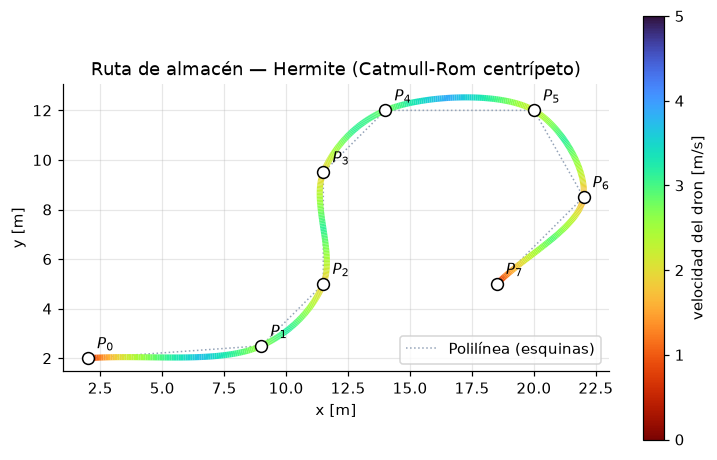

| Longitud | Tiempo estimado | κ máx | Radio mínimo |
|---|---|---|---|
| 34.23 m | 14.57 s | 0.863 1/m | 1.16 m |

In [2]:
WAYPOINTS = np.array([[2, 2], [9, 2.5], [11.5, 5], [11.5, 9.5], [14, 12], [20, 12], [22, 8.5], [18.5, 5]], float)
LIM = dict(v_cruise=5.0, a_lat_max=2.0, a_long_max=1.5)

res_h = trajectory.compute_trajectory(WAYPOINTS, "hermite", 0.0, "centripetal", samples_per_segment=80, **LIM)

def curva_coloreada(ax, res, vmax, lw=4):
    seg = np.stack([res.points[:-1], res.points[1:]], axis=1)
    lc = LineCollection(seg, cmap="turbo_r", norm=plt.Normalize(0, vmax), linewidth=lw)
    lc.set_array(0.5 * (res.v_profile[:-1] + res.v_profile[1:]))
    ax.add_collection(lc)
    return lc

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(*WAYPOINTS.T, ":", color="#94a3b8", lw=1, label="Polilínea (esquinas)")
lc = curva_coloreada(ax, res_h, LIM["v_cruise"])
ax.scatter(*WAYPOINTS.T, s=60, c="white", edgecolors="k", zorder=3)
for k, (x, y) in enumerate(WAYPOINTS):
    ax.annotate(f"$P_{k}$", (x, y), xytext=(6, 6), textcoords="offset points")
fig.colorbar(lc, ax=ax, label="velocidad del dron [m/s]")
ax.set(xlabel="x [m]", ylabel="y [m]", title="Ruta de almacén — Hermite (Catmull-Rom centrípeto)", aspect="equal")
ax.legend(loc="lower right")
guardar(fig, "01_ruta_almacen")
plt.show()

tabla([[f"{res_h.length:.2f} m", f"{res_h.time_estimate:.2f} s", f"{res_h.max_curvature:.3f} 1/m", f"{1/res_h.max_curvature:.2f} m"]],
      ["Longitud", "Tiempo estimado", "κ máx", "Radio mínimo"])

## 2. Modelado matemático

### 2.1 Parametrización
Cada coordenada se interpola contra un parámetro creciente $t$. Con $t_0 = 0$:

$$t_{k+1} = t_k + \lVert P_{k+1} - P_k\rVert^{\alpha},\qquad \alpha = 0\ (\text{uniforme}),\ 1\ (\text{cuerda}),\ \tfrac12\ (\text{centrípeta}).$$

### 2.2 Spline de Hermite cúbico
En el tramo $[t_k, t_{k+1}]$, con $\Delta_k = t_{k+1}-t_k$ y $u = (t-t_k)/\Delta_k \in [0,1]$:

$$p(u) = h_{00}(u)\,P_k + h_{10}(u)\,\Delta_k m_k + h_{01}(u)\,P_{k+1} + h_{11}(u)\,\Delta_k m_{k+1}$$

donde $m_k = p'(t_k)$ son las **tangentes** y las bases de Hermite son
$h_{00} = 2u^3-3u^2+1$, $h_{10} = u^3-2u^2+u$, $h_{01} = -2u^3+3u^2$, $h_{11} = u^3-u^2$.

Por construcción $p(t_k) = P_k$ y $p'(t_k) = m_k$ desde ambos lados ⇒ la curva es **C¹**.
La segunda derivada **no** se impone, así que en general salta en los nodos.

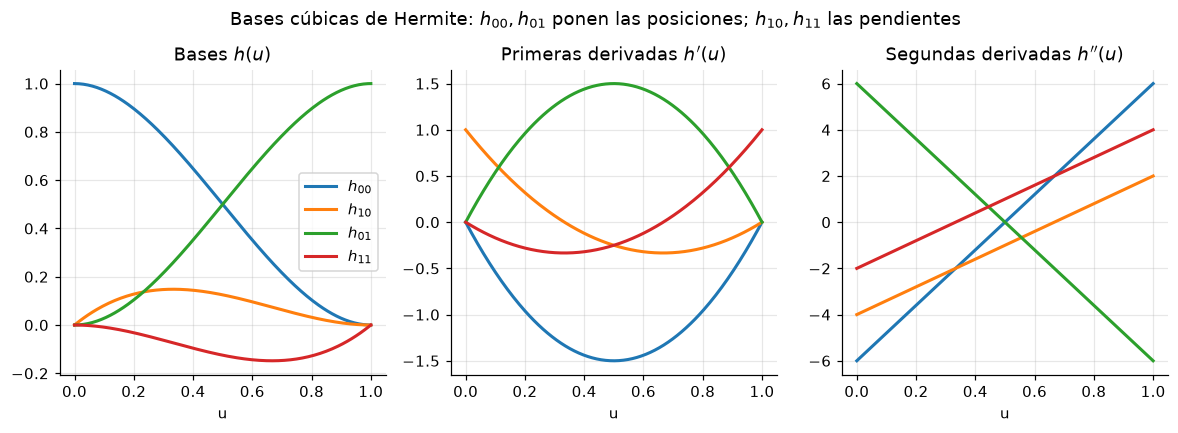

In [3]:
u = np.linspace(0, 1, 200)
fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
nombres = ["$h_{00}$", "$h_{10}$", "$h_{01}$", "$h_{11}$"]
for ax, fun, tit in zip(axs, [hermite.hermite_basis, hermite.hermite_basis_d1, hermite.hermite_basis_d2],
                        ["Bases $h(u)$", "Primeras derivadas $h'(u)$", "Segundas derivadas $h''(u)$"]):
    for h, n in zip(fun(u), nombres):
        ax.plot(u, h, label=n, lw=2)
    ax.set(title=tit, xlabel="u")
axs[0].legend()
fig.suptitle("Bases cúbicas de Hermite: $h_{00}, h_{01}$ ponen las posiciones; $h_{10}, h_{11}$ las pendientes", y=1.03)
guardar(fig, "02_bases_hermite")
plt.show()

### 2.3 Estimación de tangentes (spline cardinal)
Las tangentes $m_k$ no se conocen y se estiman con los vecinos. Con $d_k = (P_{k+1}-P_k)/\Delta_k$
(pendiente de cada tramo) y tensión $c \in [0,1]$:

$$m_k = (1-c)\,\frac{\Delta_k\, d_{k-1} + \Delta_{k-1}\, d_k}{\Delta_{k-1} + \Delta_k}$$

Es la derivada de la parábola que pasa por $P_{k-1}, P_k, P_{k+1}$ (Catmull-Rom no uniforme). Con
parametrización uniforme se reduce a la fórmula clásica $m_k = (1-c)(P_{k+1}-P_{k-1})/(t_{k+1}-t_{k-1})$.
En los extremos se usan diferencias unilaterales $m_0 = (1-c)\,d_0$ y $m_n = (1-c)\,d_{n-1}$.

### 2.4 Spline cúbico natural (comparación, C²)
Se piden también segundas derivadas continuas. Las incógnitas son $M_k = S''(t_k)$ y cumplen, para $k = 1..n-1$,

$$\Delta_{k-1} M_{k-1} + 2(\Delta_{k-1}+\Delta_k) M_k + \Delta_k M_{k+1} = 6\left[\frac{y_{k+1}-y_k}{\Delta_k} - \frac{y_k-y_{k-1}}{\Delta_{k-1}}\right]$$

con $M_0 = M_n = 0$ (natural) o con las pendientes de los extremos dadas (sujeto). Es un sistema **tridiagonal
estrictamente diagonal dominante**, que se resuelve en $O(n)$ con el **algoritmo de Thomas** sin pivoteo.

## 3. Resolución numérica: Hermite (C¹) frente a cúbico natural (C²)

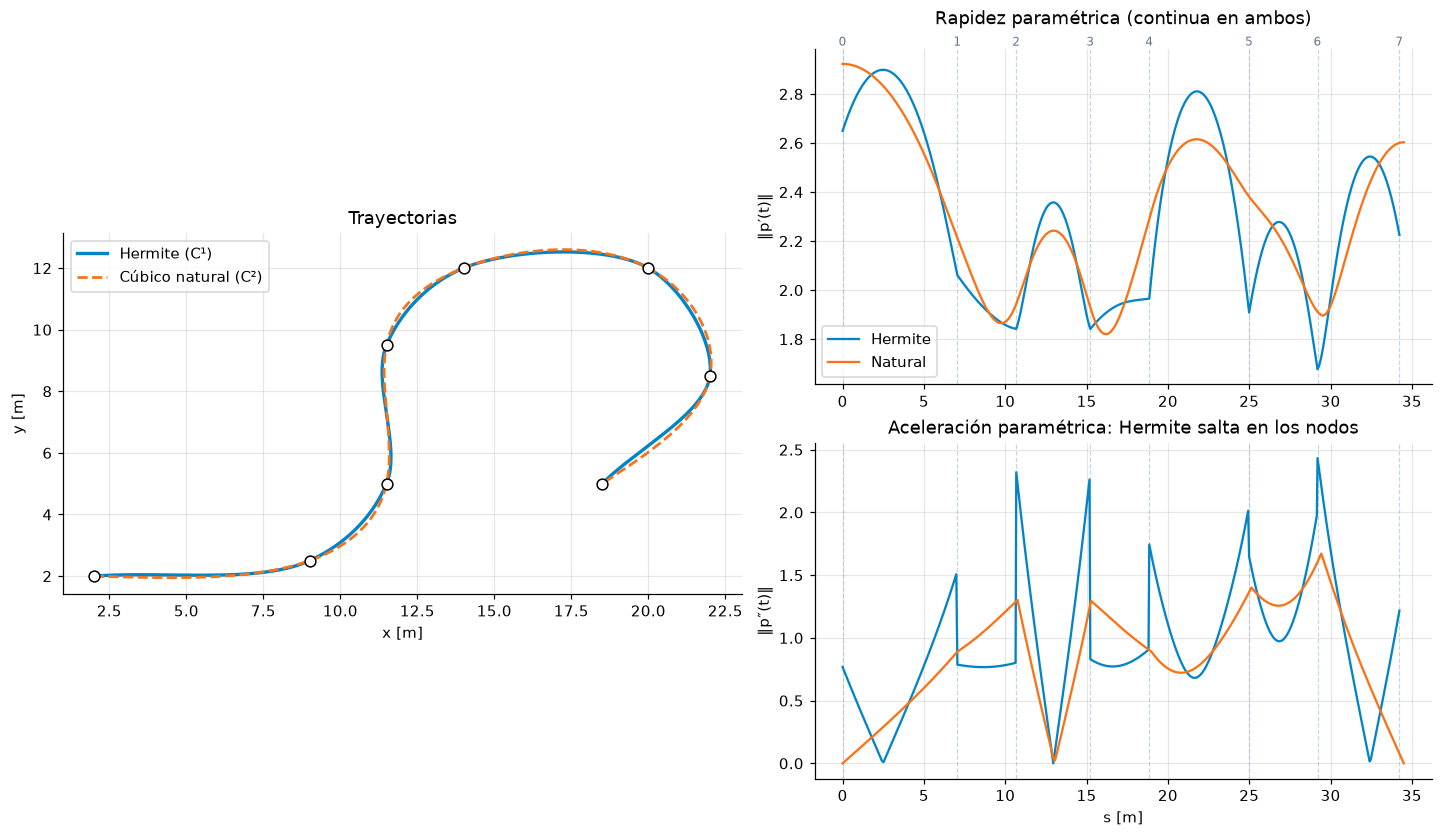

| Nodo | Salto ‖Δp″‖ Hermite | Salto ‖Δp″‖ natural |
|---|---|---|
| $P_1$ | 0.7734 | 3.5e-16 |
| $P_2$ | 1.5353 | 1.2e-15 |
| $P_3$ | 1.5545 | 1.8e-15 |
| $P_4$ | 1.3722 | 1.2e-15 |
| $P_5$ | 1.8655 | 9.0e-16 |
| $P_6$ | 1.0184 | 2.0e-15 |

In [4]:
res_n = trajectory.compute_trajectory(WAYPOINTS, "natural", 0.0, "centripetal", samples_per_segment=80, **LIM)

fig = plt.figure(figsize=(13, 7.5), layout="constrained")
gs = fig.add_gridspec(2, 2, width_ratios=[1.1, 1])
ax0 = fig.add_subplot(gs[:, 0])
ax0.plot(*res_h.points.T, color=C_HERM, lw=2.2, label="Hermite (C¹)")
ax0.plot(*res_n.points.T, color=C_NAT, lw=1.8, ls="--", label="Cúbico natural (C²)")
ax0.scatter(*WAYPOINTS.T, s=50, c="white", edgecolors="k", zorder=3)
ax0.set(aspect="equal", xlabel="x [m]", ylabel="y [m]", title="Trayectorias")
ax0.legend()

ax1 = fig.add_subplot(gs[0, 1])
ax1.plot(res_h.s, res_h.speed, color=C_HERM, label="Hermite")
ax1.plot(res_n.s, res_n.speed, color=C_NAT, label="Natural")
marcar_nodos(ax1, res_h)
ax1.set(ylabel="‖p′(t)‖")
ax1.set_title("Rapidez paramétrica (continua en ambos)", pad=16)
ax1.legend()

ax2 = fig.add_subplot(gs[1, 1])
ax2.plot(res_h.s, res_h.acceleration, color=C_HERM, label="Hermite")
ax2.plot(res_n.s, res_n.acceleration, color=C_NAT, label="Natural")
marcar_nodos(ax2, res_h, etiquetas=False)
ax2.set(xlabel="s [m]", ylabel="‖p″(t)‖", title="Aceleración paramétrica: Hermite salta en los nodos")
guardar(fig, "03_hermite_vs_natural")
plt.show()

t_nodes = parametrization.parametrize(WAYPOINTS, "centripetal")
m = tangents.cardinal_tangents(t_nodes, WAYPOINTS)
saltos_h = np.linalg.norm(hermite.second_derivative_jumps(t_nodes, WAYPOINTS, m), axis=1)
M = cubic_natural.natural_second_derivatives(t_nodes, WAYPOINTS)
saltos_n = np.linalg.norm(hermite.second_derivative_jumps(t_nodes, WAYPOINTS, cubic_natural.nodal_slopes(t_nodes, WAYPOINTS, M)), axis=1)
tabla([[f"$P_{k+1}$", f"{a:.4f}", f"{b:.1e}"] for k, (a, b) in enumerate(zip(saltos_h, saltos_n))],
      ["Nodo", "Salto ‖Δp″‖ Hermite", "Salto ‖Δp″‖ natural"])

**Interpretación.** Las dos curvas casi coinciden en posición, pero no en su segunda derivada: en Hermite
$p''$ salta en cada waypoint (tabla), mientras que en el natural el salto es cero salvo error de redondeo.
Para un dron, un salto en la aceleración es un cambio brusco de empuje (*jerk* infinito). A cambio, Hermite es
**local**: mover un waypoint solo modifica los dos tramos vecinos, mientras que el natural resuelve un sistema
global y cambia toda la curva.

## 4. Efecto de la tensión

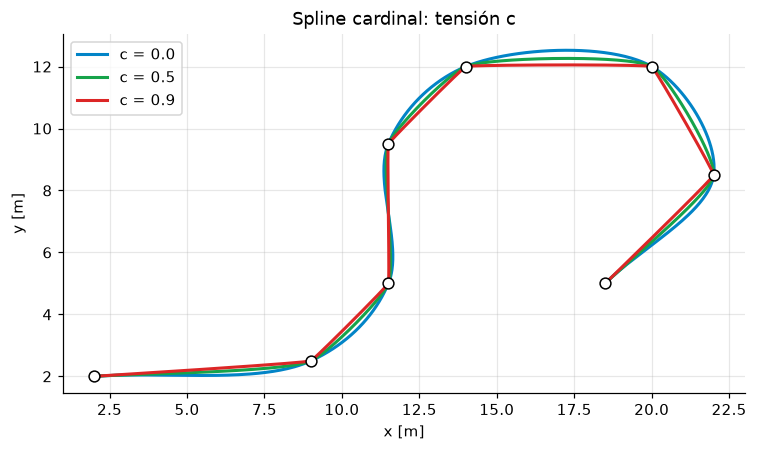

| c | Longitud [m] | Tiempo [s] | κ máx [1/m] |
|---|---|---|---|
| 0.0 | 34.23 | 14.57 | 0.863 |
| 0.5 | 33.79 | 18.70 | 4.315 |
| 0.9 | 33.59 | 23.52 | 125.123 |

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
filas = []
for c, col in zip([0.0, 0.5, 0.9], ["#0284c7", "#16a34a", "#dc2626"]):
    r = trajectory.compute_trajectory(WAYPOINTS, "hermite", c, "centripetal", samples_per_segment=80, **LIM)
    ax.plot(*r.points.T, color=col, lw=2, label=f"c = {c}")
    filas.append([c, f"{r.length:.2f}", f"{r.time_estimate:.2f}", f"{r.max_curvature:.3f}"])
ax.scatter(*WAYPOINTS.T, s=50, c="white", edgecolors="k", zorder=3)
ax.set(aspect="equal", xlabel="x [m]", ylabel="y [m]", title="Spline cardinal: tensión c")
ax.legend()
guardar(fig, "04_tension")
plt.show()
tabla(filas, ["c", "Longitud [m]", "Tiempo [s]", "κ máx [1/m]"])

Al aumentar $c$ las tangentes se reducen por $(1-c)$: la curva se ciñe a la polilínea y se acorta, pero las
esquinas se vuelven más cerradas (κ máx crece) y el dron debe frenar más. El tiempo total refleja ese
compromiso. Con $c = 1$ las tangentes son nulas: tramos rectos y parada en cada waypoint.

## 5. Efecto de la parametrización
Se usa una ruta con distancias muy desiguales entre waypoints, que es donde la parametrización importa.

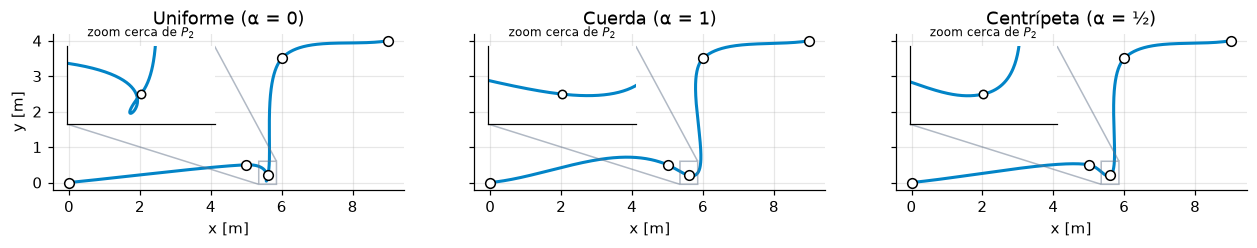

| Parametrización | Autointersecciones (bucles) | Longitud [m] | κ máx [1/m] | Tiempo [s] |
|---|---|---|---|---|
| uniform | 1 | 12.55 | 664.27 | 8.88 |
| chord | 0 | 12.44 | 5.63 | 8.37 |
| centripetal | 0 | 12.22 | 10.43 | 8.52 |

In [6]:
RUTA_DESIGUAL = np.array([[0, 0], [5, 0.5], [5.6, 0.2], [6, 3.5], [9, 4]], float)

def autointersecciones(P):
    # Cuenta cruces entre segmentos no adyacentes de la curva muestreada (detecta bucles)
    a, b = P[:-1], P[1:]
    ccw = lambda A, B, C: (C[..., 1] - A[..., 1]) * (B[..., 0] - A[..., 0]) > (B[..., 1] - A[..., 1]) * (C[..., 0] - A[..., 0])
    total = 0
    for i in range(len(a) - 2):
        A, B, C, D = a[i], b[i], a[i + 2:], b[i + 2:]
        total += int(((ccw(A, C, D) != ccw(B, C, D)) & (ccw(A, B, C) != ccw(A, B, D))).sum())
    return total

fig, axs = plt.subplots(1, 3, figsize=(14, 4.6), sharey=True)
filas = []
for ax, modo in zip(axs, ["uniform", "chord", "centripetal"]):
    r = trajectory.compute_trajectory(RUTA_DESIGUAL, "hermite", 0.0, modo, samples_per_segment=200, **LIM)
    ax.plot(*r.points.T, color=C_HERM, lw=2)
    ax.scatter(*RUTA_DESIGUAL.T, s=40, c="white", edgecolors="k", zorder=3)
    zoom = ax.inset_axes([0.04, 0.42, 0.42, 0.5])
    zoom.plot(*r.points.T, color=C_HERM, lw=2)
    zoom.scatter(*RUTA_DESIGUAL.T, s=30, c="white", edgecolors="k", zorder=3)
    zoom.set(xlim=(5.35, 5.85), ylim=(-0.05, 0.6), xticks=[], yticks=[])
    zoom.set_title("zoom cerca de $P_2$", fontsize=8)
    ax.indicate_inset_zoom(zoom, edgecolor="#64748b")
    ax.set(title={"uniform": "Uniforme (α = 0)", "chord": "Cuerda (α = 1)", "centripetal": "Centrípeta (α = ½)"}[modo],
           aspect="equal", xlabel="x [m]")
    filas.append([modo, autointersecciones(r.points), f"{r.length:.2f}", f"{r.max_curvature:.2f}", f"{r.time_estimate:.2f}"])
axs[0].set_ylabel("y [m]")
guardar(fig, "05_parametrizacion")
plt.show()
tabla(filas, ["Parametrización", "Autointersecciones (bucles)", "Longitud [m]", "κ máx [1/m]", "Tiempo [s]"])

Con parametrización **uniforme** cada tramo recibe el mismo "tiempo" aunque mida muy distinto: la tangente
estimada en $P_2$ es grande (viene de tramos largos) y el tramo corto $P_1P_2$ no alcanza a absorberla, así
que la curva **forma un bucle** (la tabla cuenta la autointersección). La de **cuerda** reparte el parámetro según
la distancia, pero exagera los tramos largos. La **centrípeta** ($\alpha = 1/2$) es el punto medio: se demuestra
que, con la tangente de Catmull-Rom no uniforme, no produce bucles ni cúspides (Yuksel et al., 2011).

## 6. Análisis de convergencia

Se comparan los splines con curvas **exactas**: un arco de círculo y la lemniscata de Bernoulli. Se toman $n+1$
waypoints equiespaciados en el parámetro $\theta$ y se usa $t_k = \theta_k$ (así las tangentes exactas
$p'(\theta_k)$ están en la misma variable). El error es $E(n) = \max_\theta \lVert S(\theta) - p(\theta)\rVert$, y
si $E \approx C h^q$ el orden $q$ es la pendiente en escala log-log.

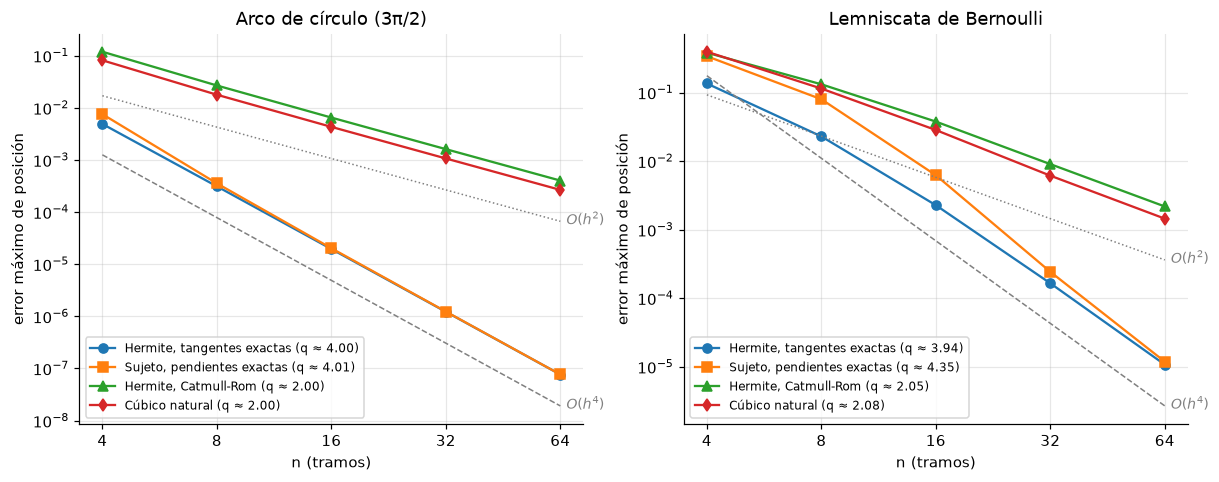

**Arco de círculo (3π/2)**

| Método | n=4 | n=8 | n=16 | n=32 | n=64 | Orden global | Orden interior |
|---|---|---|---|---|---|---|---|
| Hermite, tangentes exactas | 4.90e-03 | 3.12e-04 | 1.96e-05 | 1.22e-06 | 7.65e-08 | 4.00 | 4.00 |
| Sujeto, pendientes exactas | 7.56e-03 | 3.55e-04 | 2.03e-05 | 1.24e-06 | 7.67e-08 | 4.01 | 4.01 |
| Hermite, Catmull-Rom | 1.19e-01 | 2.68e-02 | 6.49e-03 | 1.61e-03 | 4.02e-04 | 2.00 | 3.01 |
| Cúbico natural | 8.15e-02 | 1.78e-02 | 4.31e-03 | 1.07e-03 | 2.66e-04 | 2.00 | 4.02 |

**Lemniscata de Bernoulli**

| Método | n=4 | n=8 | n=16 | n=32 | n=64 | Orden global | Orden interior |
|---|---|---|---|---|---|---|---|
| Hermite, tangentes exactas | 1.35e-01 | 2.29e-02 | 2.27e-03 | 1.65e-04 | 1.07e-05 | 3.94 | 3.94 |
| Sujeto, pendientes exactas | 3.39e-01 | 7.98e-02 | 6.22e-03 | 2.42e-04 | 1.19e-05 | 4.35 | 4.35 |
| Hermite, Catmull-Rom | 3.82e-01 | 1.32e-01 | 3.77e-02 | 9.03e-03 | 2.18e-03 | 2.05 | 3.22 |
| Cúbico natural | 3.94e-01 | 1.14e-01 | 2.84e-02 | 6.13e-03 | 1.45e-03 | 2.08 | 4.35 |

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
estilos = {"hermite_exact": ("Hermite, tangentes exactas", "o-"), "clamped_exact": ("Sujeto, pendientes exactas", "s-"),
           "catmull_rom": ("Hermite, Catmull-Rom", "^-"), "natural": ("Cúbico natural", "d-")}
resultados = {}
for ax, curva in zip(axs, [convergence.CIRCLE_ARC, convergence.LEMNISCATE]):
    r = convergence.convergence_study(curva)
    resultados[curva.name] = r
    for metodo, (nombre, est) in estilos.items():
        ax.loglog(r[metodo]["n"], r[metodo]["error"], est, label=f"{nombre} (q ≈ {r[metodo]['order']:.2f})")
    n = r["hermite_exact"]["n"].astype(float)
    for q, ls, base in [(2, ":", r["natural"]["error"][-1] * 0.25), (4, "--", r["hermite_exact"]["error"][-1] * 0.25)]:
        ref = base * (n[-1] / n) ** q
        ax.loglog(n, ref, ls, color="gray", lw=1)
        ax.annotate(f"$O(h^{q})$", (n[-1], ref[-1]), xytext=(4, -2), textcoords="offset points", color="gray", fontsize=9)
    ax.set_xticks(n, [str(int(v)) for v in n])
    ax.minorticks_off()
    ax.set(title=curva.name, xlabel="n (tramos)", ylabel="error máximo de posición")
    ax.legend(fontsize=8)
guardar(fig, "06_convergencia")
plt.show()

for nombre, r in resultados.items():
    display(Markdown(f"**{nombre}**"))
    filas = []
    for metodo, (etiqueta, _) in estilos.items():
        d = r[metodo]
        filas.append([etiqueta] + [f"{e:.2e}" for e in d["error"]] + [f"{d['order']:.2f}", f"{d['order_interior']:.2f}"])
    tabla(filas, ["Método"] + [f"n={n}" for n in r["hermite_exact"]["n"]] + ["Orden global", "Orden interior"])

**Interpretación de los órdenes** (último par de $n$, régimen asintótico):

* **Hermite con tangentes exactas: $q \approx 4$.** Es el orden teórico de la interpolación cúbica de Hermite,
  $\lVert f - p\rVert_\infty \le \frac{h^4}{384}\max|f^{(4)}|$.
* **Sujeto con pendientes exactas: $q \approx 4$.** Si las condiciones de frontera son correctas, el spline C² también es de cuarto orden.
* **Catmull-Rom: $q \approx 2$ global y $\approx 3$ en el interior.** La tangente estimada tiene error $O(h^2)$, que
  aporta $h \cdot O(h^2) = O(h^3)$ a la posición. En los extremos la diferencia unilateral solo es $O(h)$ y
  reduce el orden global a 2.
* **Natural: $q \approx 2$ global y $\approx 4$ en el interior.** La condición $M_0 = M_n = 0$ es falsa (el círculo
  tiene curvatura en sus extremos), y ese error de frontera domina cerca de los bordes.

Conclusión: **las condiciones de frontera, no el esquema interior, limitan la precisión global** de los
métodos con derivadas estimadas.

## 7. Perfil de velocidad y tiempo estimado

1. **Límite lateral** (no derrapar en las curvas): $v_{max}(s) = \min\left(v_{crucero},\ \sqrt{a_{lat,max}/\kappa(s)}\right)$, con
   $\kappa = |x'y'' - y'x''| / (x'^2+y'^2)^{3/2}$.
2. **Límite longitudinal** (acelerar y frenar a tiempo): pasada hacia adelante $v_i^2 \le v_{i-1}^2 + 2a_{long}\Delta s_i$ y
   pasada hacia atrás, partiendo y terminando en reposo.
3. **Tiempo**: entre muestras la aceleración es constante, así que $\Delta t_i = \dfrac{2\,\Delta s_i}{v_{i-1}+v_i}$ y $T = \sum \Delta t_i$.

La longitud de arco $s(t) = \int \lVert p'(\tau)\rVert d\tau$ se calcula con **Simpson compuesto**.

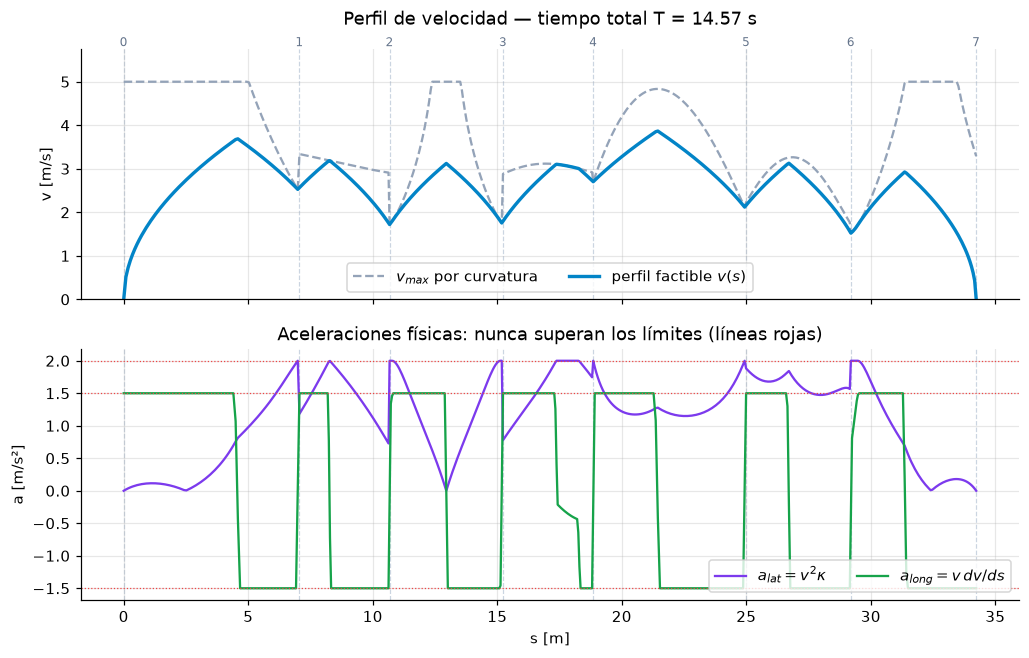

| a_lat máx [m/s²] | |a_long| máx [m/s²] | Tiempo factible | Tiempo ideal a v_crucero |
|---|---|---|---|
| 2.000 ≤ 2.0 | 1.500 ≤ 1.5 | 14.57 s | 6.85 s |

In [8]:
a_lat, a_long = kinematics.physical_accelerations(res_h.s, res_h.v_profile, res_h.curvature)

fig, axs = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
axs[0].plot(res_h.s, res_h.v_max, "--", color=C_LIM, label="$v_{max}$ por curvatura")
axs[0].plot(res_h.s, res_h.v_profile, color=C_HERM, lw=2.2, label="perfil factible $v(s)$")
marcar_nodos(axs[0], res_h)
axs[0].set(ylabel="v [m/s]", ylim=(0, LIM["v_cruise"] * 1.15),
           )
axs[0].set_title(f"Perfil de velocidad — tiempo total T = {res_h.time_estimate:.2f} s", pad=16)
axs[0].legend(loc="lower center", ncol=2)

axs[1].plot(res_h.s, a_lat, color="#7c3aed", label="$a_{lat} = v^2\\kappa$")
axs[1].plot(res_h.s, a_long, color="#16a34a", label="$a_{long} = v\\,dv/ds$")
for y in (LIM["a_lat_max"], LIM["a_long_max"], -LIM["a_long_max"]):
    axs[1].axhline(y, color="#ef4444", lw=0.8, ls=":")
marcar_nodos(axs[1], res_h, etiquetas=False)
axs[1].set(xlabel="s [m]", ylabel="a [m/s²]", title="Aceleraciones físicas: nunca superan los límites (líneas rojas)")
axs[1].legend(loc="lower right", ncol=2)
guardar(fig, "07_perfil_velocidad")
plt.show()

tabla([[f"{a_lat.max():.3f} ≤ {LIM['a_lat_max']}", f"{np.abs(a_long).max():.3f} ≤ {LIM['a_long_max']}",
        f"{res_h.time_estimate:.2f} s", f"{res_h.length / LIM['v_cruise']:.2f} s"]],
      ["a_lat máx [m/s²]", "|a_long| máx [m/s²]", "Tiempo factible", "Tiempo ideal a v_crucero"])

### Reparametrización por longitud de arco
Para animar el dron a velocidad real hay que responder: *¿qué $t$ corresponde a la distancia $s^*$?* Se resuelve
$s(t) - s^* = 0$ con **Newton** ($s'(t) = \lVert p'(t)\rVert$), con bisección de respaldo. Con $t$ equiespaciado
los puntos se amontonan donde la rapidez paramétrica es baja; con $s$ equiespaciado quedan a la misma distancia.

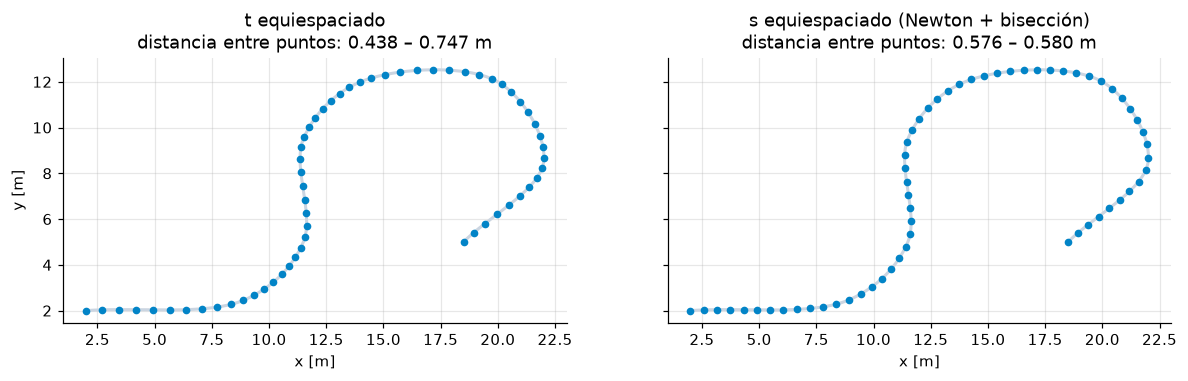

In [9]:
sp = trajectory.build_spline(WAYPOINTS, "hermite", 0.0, "centripetal")
N = 60
t_unif = np.linspace(sp.t_nodes[0], sp.t_nodes[-1], N)
L = res_h.length
t_arc = arc_length.reparametrize_by_arc_length(sp.t_nodes, sp.speed, np.linspace(0, L, N))

fig, axs = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for ax, tt, tit in zip(axs, [t_unif, t_arc], ["t equiespaciado", "s equiespaciado (Newton + bisección)"]):
    pts = sp.evaluate(tt)[0]
    ax.plot(*res_h.points.T, color="#cbd5e1", lw=2)
    ax.plot(*pts.T, "o", ms=4, color=C_HERM)
    d = np.linalg.norm(np.diff(pts, axis=0), axis=1)
    ax.set(title=f"{tit}\ndistancia entre puntos: {d.min():.3f} – {d.max():.3f} m", aspect="equal", xlabel="x [m]")
axs[0].set_ylabel("y [m]")
guardar(fig, "08_reparametrizacion")
plt.show()

## 8. Conclusiones

1. El **spline de Hermite cúbico** interpola los waypoints con continuidad C¹ y control **local**: cada tramo
   depende solo de sus dos waypoints y sus tangentes. Eso lo hace ideal para la edición interactiva.
2. Las **tangentes** (Catmull-Rom/cardinal) y la **parametrización** (la centrípeta evita bucles) determinan la forma.
   La tensión intercambia longitud del recorrido por curvatura.
3. El **spline cúbico natural** agrega continuidad C², sin saltos de aceleración, a cambio de resolver un sistema
   tridiagonal global (Thomas, $O(n)$) y de depender de condiciones de frontera artificiales.
4. El estudio de convergencia confirma el **orden 4** con derivadas exactas y muestra que las condiciones de
   frontera reducen el orden global a 2 cuando las derivadas se estiman.
5. Con la curvatura y la longitud de arco (Simpson) se construye un **perfil de velocidad factible**: el dron
   frena antes de las curvas cerradas, acelera en las rectas y nunca supera $a_{lat}$ ni $a_{long}$.